# Support Vector Machine: recognizing handwritten digits

**Goal.** Find the boundary with the largest margin between classes.

**The model.** Only the points closest to the boundary, the **support vectors**, define it.
The **kernel trick** allows curved boundaries. Two settings matter:
- `C`: how strongly errors are punished.
- `gamma` (RBF kernel): how local the influence of one sample is.

**The dataset.** *Optical Recognition of Handwritten Digits* (UCI): 5,620 images of 8x8 pixels with an official train/test split.

In [1]:
# SETUP: install any package this notebook needs but your Python does not have.
# It uses the same Python that runs this notebook, so it also works on Windows
# inside a virtual environment or Anaconda.
import importlib.util
import subprocess
import sys

required = {  # import name -> pip package name
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "sklearn": "scikit-learn",
    "certifi": "certifi"
}
missing = [pip for module, pip in required.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("All required packages are already installed.")

All required packages are already installed.


In [2]:
# A consistent look for every figure, and a fixed random seed so that
# running the notebook twice gives the same numbers.
import warnings
import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

PURPLE, BLUE, GREEN, ORANGE, RED = "#5A28C8", "#476ADD", "#00A651", "#F28C28", "#E0344B"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 12, "axes.titleweight": "bold", "axes.titlecolor": PURPLE,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

## 1. Get the data

In [3]:
# DOWNLOAD THE DATASET
# Files are stored next to this notebook in a "data" folder, and are only
# downloaded the first time. pathlib builds correct paths on Windows.
#
# Why certifi? Some Windows machines have an out-of-date certificate store and
# fail with CERTIFICATE_VERIFY_FAILED. certifi ships an up-to-date list of trusted
# authorities, so the secure connection is still fully verified.
import shutil
import ssl
import urllib.request
import zipfile
from pathlib import Path

import certifi

def download(url, destination):
    """Download url to destination unless the file already exists."""
    destination = Path(destination)
    if destination.exists():
        print("Already downloaded:", destination)
        return destination
    destination.parent.mkdir(parents=True, exist_ok=True)
    print("Downloading:", url)
    context = ssl.create_default_context(cafile=certifi.where())
    request = urllib.request.Request(url, headers={"User-Agent": "python"})
    temporary = destination.with_suffix(destination.suffix + ".part")
    with urllib.request.urlopen(request, context=context, timeout=600) as response, open(temporary, "wb") as output:
        shutil.copyfileobj(response, output)
    temporary.replace(destination)  # only a complete file gets the final name
    print("Saved:", destination, f"({destination.stat().st_size / 1e6:.1f} MB)")
    return destination

DATA_DIR = Path("data") / "optdigits"
archive = download("https://archive.ics.uci.edu/static/public/80/optical+recognition+of+handwritten+digits.zip", DATA_DIR / "dataset.zip")
with zipfile.ZipFile(archive) as z:
    z.extractall(DATA_DIR)
print("Files:", [p.name for p in DATA_DIR.rglob("*") if p.is_file()][:10])

Downloading: https://archive.ics.uci.edu/static/public/80/optical+recognition+of+handwritten+digits.zip


Saved: data\optdigits\dataset.zip (0.6 MB)
Files: ['dataset.zip', 'optdigits-orig.cv.Z', 'optdigits-orig.names', 'optdigits-orig.tra.Z', 'optdigits-orig.wdep.Z', 'optdigits-orig.windep.Z', 'optdigits.names', 'optdigits.tes', 'optdigits.tra', 'readme.txt']


In [4]:
import pandas as pd

# 64 features: an 8x8 image, each cell counting the ink from 0 to 16. Column 64 is the digit.
train = pd.read_csv(DATA_DIR / "optdigits.tra", header=None)
test = pd.read_csv(DATA_DIR / "optdigits.tes", header=None)
X_train, y_train = train.iloc[:, :64].to_numpy(), train.iloc[:, 64].to_numpy()
X_test, y_test = test.iloc[:, :64].to_numpy(), test.iloc[:, 64].to_numpy()
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (3823, 64) Test: (1797, 64)


## 2. Tune C and gamma with a grid search
Scaling is placed inside the pipeline, so each cross-validation fold is scaled using only its own training part. This prevents data leakage.

In [5]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

C_values = [0.1, 1, 10, 100]
gamma_values = [0.0001, 0.001, 0.01, 0.1]
search = GridSearchCV(make_pipeline(StandardScaler(), SVC()),
                      {"svc__C": C_values, "svc__gamma": gamma_values}, cv=3, n_jobs=-1)
search.fit(X_train, y_train)
print("Best settings:", search.best_params_, "| CV accuracy:", round(search.best_score_, 4))
heatmap = search.cv_results_["mean_test_score"].reshape(len(C_values), len(gamma_values))

Best settings: {'svc__C': 10, 'svc__gamma': 0.01} | CV accuracy: 0.9864


## 3. Test, and compare with a linear SVM

In [6]:
from sklearn.metrics import accuracy_score, confusion_matrix

model = search.best_estimator_
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
linear_accuracy = make_pipeline(StandardScaler(), SVC(kernel="linear")).fit(X_train, y_train).score(X_test, y_test)
n_support = int(model.named_steps["svc"].n_support_.sum())
print(f"RBF: {accuracy:.4f} | Linear: {linear_accuracy:.4f} | Support vectors: {n_support} of {len(X_train)}")

RBF: 0.9705 | Linear: 0.9594 | Support vectors: 1043 of 3823


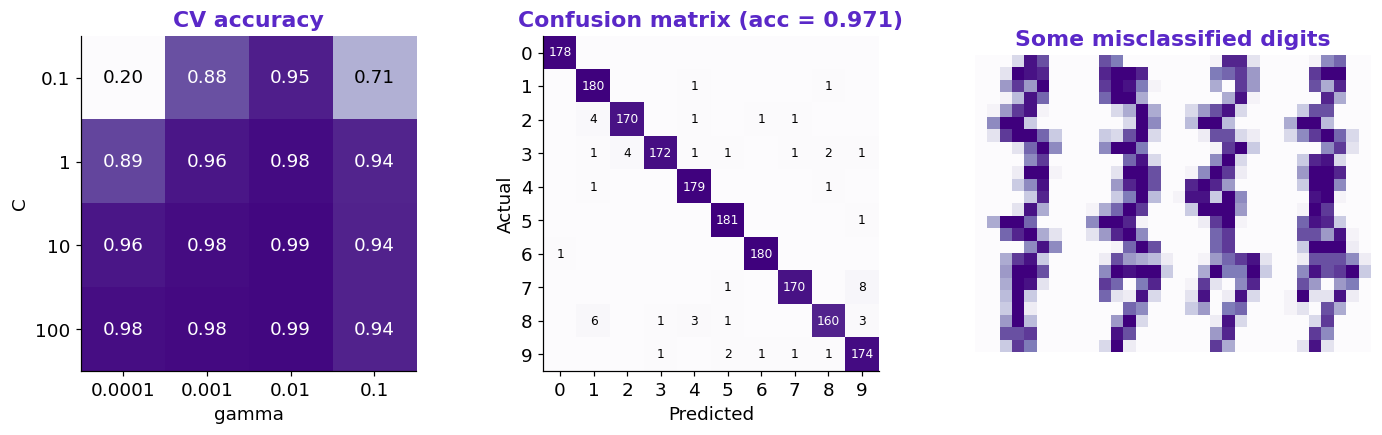

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4))

im = ax[0].imshow(heatmap, cmap="Purples", vmin=0.5, vmax=1)
for (i, j), v in np.ndenumerate(heatmap):
    ax[0].text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v > 0.8 else "black")
ax[0].set(title="CV accuracy", xticks=range(4), yticks=range(4), xticklabels=gamma_values, yticklabels=C_values, xlabel="gamma", ylabel="C")

ax[1].imshow(cm, cmap="Purples")
for (i, j), v in np.ndenumerate(cm):
    if v:
        ax[1].text(j, i, v, ha="center", va="center", fontsize=8, color="white" if v > cm.max() / 2 else "black")
ax[1].set(title=f"Confusion matrix (acc = {accuracy:.3f})", xticks=range(10), yticks=range(10), xlabel="Predicted", ylabel="Actual")

# Show a montage of the images the model got wrong.
wrong = np.where(y_pred != y_test)[0][:12]
montage = np.vstack([np.hstack([X_test[i].reshape(8, 8) for i in wrong[r * 4:(r + 1) * 4]]) for r in range(3)])
ax[2].imshow(montage, cmap="Purples")
ax[2].set(title="Some misclassified digits")
ax[2].axis("off")
fig.tight_layout()
plt.show()

In [8]:
# SAVE THE RESULTS. The figure and the metrics are written to a "results" folder.
# These exact files are what the course slides show.
import json

results_dir = Path("results")
results_dir.mkdir(exist_ok=True)
fig.savefig(results_dir / "05_svm.png", dpi=170, bbox_inches="tight", facecolor="white")

results = {
    "model": "SVM (RBF kernel)",
    "dataset": "Optical Digits (UCI)",
    "n_samples": int(len(X_train) + len(X_test)),
    "metrics": {"RBF accuracy": round(accuracy, 4), "Linear accuracy": round(linear_accuracy, 4), "Best C": search.best_params_["svc__C"], "Best gamma": search.best_params_["svc__gamma"]},
}
(results_dir / "05_svm.json").write_text(json.dumps(results, indent=2), encoding="utf-8")
print(json.dumps(results, indent=2))

{
  "model": "SVM (RBF kernel)",
  "dataset": "Optical Digits (UCI)",
  "n_samples": 5620,
  "metrics": {
    "RBF accuracy": 0.9705,
    "Linear accuracy": 0.9594,
    "Best C": 10,
    "Best gamma": 0.01
  }
}


## What to remember
- `C` and `gamma` must be tuned together.
- SVMs are excellent on medium-sized data, but training gets slow beyond roughly 100,000 samples.